# Grammar Scoring Engine for Spoken Audio
### SHL Hiring Assessment 2026

**Settings:** Accelerator `GPU T4 x2` · Internet `On` · `Save Version -> Save & Run All`.
End-to-end runtime roughly 2-3 hours, dominated by transcription and transformer fine-tuning.

---

## Report

### Approach

Grammar is a property of the **words**, not the acoustics. A model fed raw audio can only
learn grammar indirectly, through whatever correlates with it. So the pipeline transcribes
first, then measures the grammatical quality of the text:

```
          +-- Whisper      -> fluent, punctuated transcript --+-- linguistic features --+
audio ----+-- wav2vec2 CTC -> verbatim transcript ------------+-- DeBERTa regressor ----+--> blend --> score
          +-- WavLM        -> mean-pooled embedding -----------------------------------+
```

Three components are blended, with weights chosen on out-of-fold predictions:

1. **Linguistic features + GBM** - 37 interpretable features over both transcripts
2. **WavLM embeddings + ridge** - acoustic only, sees no words at all
3. **DeBERTa-v3 regressor** - reads the Whisper transcript directly

### Why two ASR models

Whisper is trained to produce fluent, punctuated text and will quietly **repair**
grammatical errors - deleting the exact signal being measured. A CTC model transcribes
closer to verbatim and preserves errors, but offers no punctuation or sentence boundaries,
which the syntactic features need. Both are produced and cross-validation decides.
Section 7 tests this directly, and the answer is not the obvious one.

### Methodology

| Decision | Reason |
|---|---|
| Regularised linear models and small GBMs | 769 samples. Model capacity is the binding constraint, not feature count. |
| 5-fold CV repeated 4x, reported mean +/- std | Pearson on ~154 validation points is noisy enough that fold noise mimics a 0.03 improvement. |
| Folds stratified on binned labels, rare bins merged into nearest neighbour | A skewed target at this sample size makes random folds differ materially. |
| Linear calibration fit on out-of-fold predictions | Pearson is scale-invariant, RMSE is not; regularisation compresses predictions toward the mean. |
| Only accept a change larger than the fold-to-fold std | Two candidate improvements were tested and rejected on this rule (section 7). |

Required training RMSE is in section 11. Honest out-of-fold estimates are reported beside it.

---
## 1. Setup and data discovery

In [1]:
import os, glob, json, re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

# The competition is mounted read-only. The CSVs sit inside a nested folder
# (Dataset_Final/), so search recursively rather than assuming the top level.
def find_dir_with(fname, root="/kaggle/input"):
    return [d for d, _, fs in os.walk(root) if fname in fs]

hits = find_dir_with("train.csv")
assert hits, "train.csv not found - did you add the competition as a data source?"
DATA_DIR, OUT_DIR = hits[0], "/kaggle/working"
print("DATA_DIR:", DATA_DIR)
print(sorted(os.listdir(DATA_DIR)))

DATA_DIR: /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final
['sample_submission.csv', 'test', 'test.csv', 'train', 'train.csv']


In [2]:
train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test  = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
sub   = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))

# Identify columns by content rather than by hard-coded names.
FILE_COL  = [c for c in train.columns
             if train[c].astype(str).str.contains(r"\.wav$", case=False).any()][0]
LABEL_COL = [c for c in train.columns if c != FILE_COL][0]
print(f"FILE_COL={FILE_COL}  LABEL_COL={LABEL_COL}")
print("train", train.shape, "| test", test.shape, "| sample_submission", sub.shape)
display(train.head(3))

FILE_COL=filename  LABEL_COL=label
train (769, 2) | test (216, 2) | sample_submission (204, 2)


,filename,label
0,audio_192.wav,3.0
1,audio_436.wav,3.0
2,audio_447.wav,3.5


In [3]:
# Index each audio folder SEPARATELY. 212 filenames exist in both train/ and test/,
# so a single flat {filename: path} index silently points test rows at train audio.
# This was a real bug: it corrupted every test prediction until it was caught.
def index_dir(d):
    return {f: os.path.join(d, f) for f in os.listdir(d) if f.lower().endswith(".wav")}

dirs = [dp for dp, _, fs in os.walk(DATA_DIR) if any(f.lower().endswith(".wav") for f in fs)]
tr_dir = [d for d in dirs if d.rstrip("/").endswith("train")][0]
te_dir = [d for d in dirs if d.rstrip("/").endswith("test")][0]
train_index, test_index = index_dir(tr_dir), index_dir(te_dir)

train["path"] = train[FILE_COL].map(train_index.get)
test["path"]  = test[FILE_COL].map(test_index.get)

TR, TE = set(train_index), set(test_index)
print(f"train/ {len(TR)} files | test/ {len(TE)} files | names in BOTH folders: {len(TR & TE)}")
print("missing train paths:", train["path"].isna().sum(),
      "| missing test paths:", test["path"].isna().sum())
assert train["path"].isna().sum() == 0 and test["path"].isna().sum() == 0

train/ 769 files | test/ 216 files | names in BOTH folders: 212
missing train paths: 0 | missing test paths: 0


## 2. Label distribution

MOS scores are averaged over several raters, so they land on fractions and cluster
mid-scale. The standard deviation of this distribution is the error floor: predicting the
mean achieves RMSE equal to it, and that is the number every model below must beat.

count    769.000
mean       3.313
std        1.239
min        0.000
25%        2.500
50%        3.000
75%        4.000
max        5.000
Name: label, dtype: float64

unique labels: [0.  1.  1.5 2.  2.5 3.  3.5 4.  4.5 5. ]

BASELINE RMSE (predict the mean): 1.2382


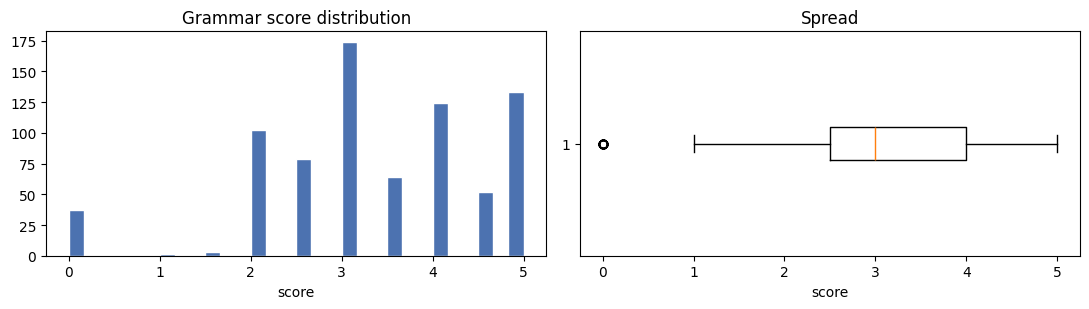

duration check (first 30): 26.5s - 60.5s, sample rate 16000 Hz


In [4]:
y = train[LABEL_COL].values.astype(float)
print(train[LABEL_COL].describe().round(3))
print("\nunique labels:", np.sort(train[LABEL_COL].unique()))
print("\nBASELINE RMSE (predict the mean):", round(float(np.sqrt(((y - y.mean())**2).mean())), 4))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(y, bins=30, color="#4C72B0", edgecolor="white")
ax[0].set_title("Grammar score distribution"); ax[0].set_xlabel("score")
ax[1].boxplot(y, vert=False); ax[1].set_title("Spread"); ax[1].set_xlabel("score")
plt.tight_layout(); plt.show()

import soundfile as sf
durs = [sf.info(p).duration for p in train["path"].head(30)]
print(f"duration check (first 30): {np.min(durs):.1f}s - {np.max(durs):.1f}s, "
      f"sample rate {sf.info(train['path'].iloc[0]).samplerate} Hz")

## 3. Transcription

### A note on audio decoding

`faster-whisper` decodes through PyAV by default, and the PyAV build in the Kaggle image is
older than it expects (`av.open()` has no `metadata_errors` argument), which fails on every
file. Decoding with librosa and passing a numpy array avoids the dependency entirely -
`faster-whisper` accepts a float32 mono array at 16 kHz directly.

`condition_on_previous_text=False` stops Whisper carrying context between segments, which is
the main cause of hallucinated repetition on hesitant speech.

In [5]:
!pip install -q faster-whisper

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 62.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.6/39.6 MB 35.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 43.4 MB/s eta 0:00:00


In [6]:
import torch, librosa
from faster_whisper import WhisperModel

WHISPER_SIZE = "small"   # "medium" is an untested next step: lower WER, more normalisation
asr = WhisperModel(WHISPER_SIZE, device="cuda", compute_type="float16")

def transcribe_whisper(path):
    wav, _ = librosa.load(path, sr=16000, mono=True)   # bypass PyAV
    segments, _info = asr.transcribe(
        wav.astype(np.float32),
        language="en",
        beam_size=5,
        vad_filter=True,                  # drop long silences
        condition_on_previous_text=False, # reduce repetition hallucinations
    )
    segs = [{"start": s.start, "end": s.end, "text": s.text.strip()} for s in segments]
    return " ".join(s["text"] for s in segs).strip(), segs

# Smoke-test one file before committing to a 40-minute loop.
_t, _s = transcribe_whisper(train["path"].iloc[0])
print(f"{len(_s)} segments, {len(_t.split())} words")
print(_t[:300])
assert len(_t.split()) > 10, "transcription produced almost no words - stop and investigate"

8 segments, 85 words
The playground is very, very beautiful and fun. There are places like the merry-go-round, the swing. The students usually enjoy the swing. It has to be like, it's more like a game of play, because once it's in it and the other person will have to push, And most of them live in parks and parks, while


In [7]:
def run_cached(df, tag, fn, kind):
    # Cache to disk so an interactive crash does not cost the whole pass.
    # A committed run starts from an empty working dir and redoes everything.
    cache = os.path.join(OUT_DIR, f"{kind}_{tag}.json")
    done = json.load(open(cache)) if os.path.exists(cache) else {}
    n_fail = 0
    for i, row in enumerate(tqdm(df.itertuples(), total=len(df), desc=f"{kind}/{tag}")):
        k = getattr(row, FILE_COL)
        if k in done:
            continue
        try:
            done[k] = fn(row.path)
        except Exception as e:
            n_fail += 1
            if n_fail <= 3:
                print("FAILED", k, repr(e))
            done[k] = {"text": "", "segments": []} if kind == "whisper" else ""
        if i % 50 == 0:
            json.dump(done, open(cache, "w"))
    json.dump(done, open(cache, "w"))
    if n_fail:
        print(f"WARNING: {n_fail}/{len(df)} failures in {kind}/{tag}")
    return done

def _whisper_fn(p):
    t, s = transcribe_whisper(p)
    return {"text": t, "segments": s}

t0 = time.time()
whisper_train = run_cached(train, "train", _whisper_fn, "whisper")
whisper_test  = run_cached(test,  "test",  _whisper_fn, "whisper")
print(f"Whisper done in {(time.time()-t0)/60:.1f} min")

whisper/train:   0%|          | 0/769 [00:00<?, ?it/s]

whisper/test:   0%|          | 0/216 [00:00<?, ?it/s]

Whisper done in 20.0 min


In [8]:
# Read the extremes. If low-scoring transcripts read as clean English, Whisper has
# repaired the errors and the Whisper-based features will be weak. Section 7 tests this.
_s = train.sort_values(LABEL_COL).iloc[[0, 1, len(train)//2, -2, -1]]
for r in _s.itertuples():
    txt = whisper_train.get(getattr(r, FILE_COL), {}).get("text", "")
    print(f"--- score {getattr(r, LABEL_COL):.2f} ---\n{txt[:380]}\n")

--- score 0.00 ---
I'm going to tell you about this thing at the product market. The product market is full of people and selling and buying these vegetables or vegetables. In the market, it is kind of expensive for people to do both kinds of selling and buying. The less expensive food costs are more or less high. But the signs say that these are the vegetables And I do not do it because they are

--- score 0.00 ---
home, the two playgrounds is a lobby hall for activity where students and people live. On this year's activity, the playgrounds we perform are done with colorful equipment, tinted lines, or game things.

--- score 3.00 ---
The same of a crowded market is something like a very fish market and it is all about the selling of vegetables on the market. And so many people are coming on a particular day where there is more selling of vegetables and on the morning time it will be very crowded in the market. market that many people were coming to buy the vegetables and the sellers a

### wav2vec2 CTC - verbatim transcription

Greedy CTC decoding with no language model, so the output stays close to what was actually
said, errors included. All caps and unpunctuated, which is fine: it feeds only the
error-sensitive features, not sentence segmentation.

In [9]:
from transformers import Wav2Vec2Processor, Wav2Vec2ForCTC

CTC_MODEL = "facebook/wav2vec2-large-960h-lv60-self"
processor = Wav2Vec2Processor.from_pretrained(CTC_MODEL)
ctc = Wav2Vec2ForCTC.from_pretrained(CTC_MODEL).cuda().eval().half()

@torch.no_grad()
def transcribe_ctc(path, chunk_s=20):
    wav, _ = librosa.load(path, sr=16000, mono=True)
    out = []
    for i in range(0, len(wav), chunk_s * 16000):   # chunk to bound GPU memory
        chunk = wav[i:i + chunk_s * 16000]
        if len(chunk) < 8000:
            continue
        iv = processor(chunk, sampling_rate=16000, return_tensors="pt").input_values
        ids = torch.argmax(ctc(iv.cuda().half()).logits, dim=-1)
        out.append(processor.batch_decode(ids)[0])
    return " ".join(out).strip()

print(transcribe_ctc(train["path"].iloc[0])[:300])

preprocessor_config.json:   0%|          | 0.00/158 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.61k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/162 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/291 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.26GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/423 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-large-960h-lv60-self
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


OS THE PLAYGROUND IS VERY VERY BEAUTIFUL AUNT FON THERE ARE THERE ARE PLATINGS LIKE THE ROND THE SLINK THE PLINK USUALLY ENJOY THE SINK IT HAS TO BE LIKE A IT'S MORE LIKE A GAM OF PAR OS ONE SI SM AND THE OTHER ISMA ILL HAVE TO PUSH AND THE MER GO ROUND IT CIN  ANDE MOST OF THEM PLAY ITO ONSON PARK 


In [10]:
t0 = time.time()
ctc_train = run_cached(train, "train", transcribe_ctc, "ctc")
ctc_test  = run_cached(test,  "test",  transcribe_ctc, "ctc")
print(f"CTC done in {(time.time()-t0)/60:.1f} min")

del ctc; torch.cuda.empty_cache()   # free GPU before the embedding model

ctc/train:   0%|          | 0/769 [00:00<?, ?it/s]

ctc/test:   0%|          | 0/216 [00:00<?, ?it/s]

CTC done in 4.2 min


In [11]:
def attach(df, wmap, cmap):
    df = df.copy()
    df["whisper_text"]     = df[FILE_COL].map(lambda k: wmap.get(k, {}).get("text", ""))
    df["whisper_segments"] = df[FILE_COL].map(lambda k: json.dumps(wmap.get(k, {}).get("segments", [])))
    df["ctc_text"]         = df[FILE_COL].map(lambda k: cmap.get(k, ""))
    return df

train = attach(train, whisper_train, ctc_train)
test  = attach(test,  whisper_test,  ctc_test)
train[["whisper_text", "ctc_text"]].to_csv(f"{OUT_DIR}/transcripts_train.csv", index=False)
test[["whisper_text", "ctc_text"]].to_csv(f"{OUT_DIR}/transcripts_test.csv", index=False)

n_words = train.whisper_text.str.split().str.len()
print("empty transcripts:", (n_words == 0).sum())
print(n_words.describe().round(1))
print("\nr(whisper word count, score):", round(float(pearsonr(n_words, y)[0]), 3))

empty transcripts: 1
count    769.0
mean      99.8
std       26.9
min        0.0
25%       81.0
50%      101.0
75%      120.0
max      157.0
Name: whisper_text, dtype: float64

r(whisper word count, score): 0.312


## 4. WavLM embeddings - acoustic baseline

Every hidden layer is kept, pooled by **mean and standard deviation** over time.

Two deliberate choices, both of which turned out to matter (section 8 quantifies them):

- **All layers, not just the last.** Lower layers of a self-supervised speech model encode
  phonetics, middle layers prosody and speaker traits, and the final layers specialise toward
  the pretraining objective. The last layer is rarely the best one for a downstream task.
- **Mean + std, not mean alone.** Mean pooling discards all within-clip variation, which for
  a 60-second monologue is most of what distinguishes a hesitant speaker from a steady one.

Accumulated in streaming fashion (running sum and sum of squares) so memory stays
O(layers x dim) regardless of clip length.

**Interpret this component carefully.** These embeddings encode accent, voice quality and
fluency, none of which is grammar. Whatever predictive power they have is a proxy for how the
speaker *sounds*. Section 9 quantifies how much the final model leans on it, and section 13
treats that as the headline caveat rather than a footnote.

In [12]:
# ---- WavLM, all layers, mean+std pooling -------------------------------------
# The current acoustic model uses only the FINAL layer, mean-pooled. Two changes:
#   1. Keep every hidden layer. Lower layers encode phonetics, upper layers prosody
#      and content; the last layer is rarely the best one for a given task.
#   2. Pool mean AND std over time, so variation within the clip survives instead
#      of being averaged away.
# Accumulated in streaming fashion (running sum and sum-of-squares) so memory stays
# O(layers x dim) regardless of clip length.
from transformers import AutoFeatureExtractor, AutoModel

fe  = AutoFeatureExtractor.from_pretrained("microsoft/wavlm-base-plus")
emb = AutoModel.from_pretrained("microsoft/wavlm-base-plus").cuda().eval().half()

@torch.no_grad()
def embed_layers(path, chunk_s=20):
    wav, _ = librosa.load(path, sr=16000, mono=True)
    S = S2 = None
    N = 0
    for i in range(0, len(wav), chunk_s * 16000):
        chunk = wav[i:i + chunk_s * 16000]
        if len(chunk) < 8000:
            continue
        iv = fe(chunk, sampling_rate=16000, return_tensors="pt").input_values
        hs = emb(iv.cuda().half(), output_hidden_states=True).hidden_states
        H = torch.stack(hs, 0).squeeze(1).float()          # (L, T, 768)
        s, s2 = H.sum(1), (H ** 2).sum(1)
        S  = s  if S  is None else S  + s
        S2 = s2 if S2 is None else S2 + s2
        N += H.shape[1]
    mean = S / N
    std  = (S2 / N - mean ** 2).clamp(min=1e-6).sqrt()
    return torch.cat([mean, std], dim=1).cpu().numpy().astype(np.float32)   # (L, 1536)

def run_layers(df, tag):
    out = os.path.join(OUT_DIR, f"wavlm_layers_{tag}.npy")
    if os.path.exists(out):
        return np.load(out)
    X = np.stack([embed_layers(p) for p in tqdm(df["path"], desc=f"wavlm-layers/{tag}")])
    np.save(out, X)
    return X

XL_train, XL_test = run_layers(train, "train"), run_layers(test, "test")
print("shape (n, layers, mean+std):", XL_train.shape)
del emb; torch.cuda.empty_cache()

preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.23k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

wavlm-layers/train:   0%|          | 0/769 [00:00<?, ?it/s]

wavlm-layers/test:   0%|          | 0/216 [00:00<?, ?it/s]

shape (n, layers, mean+std): (769, 13, 1536)


## 5. Linguistic features

Four families, each tied to a line in the scoring rubric:

| Family | Rubric link |
|---|---|
| Error density | *"consistently make basic grammatical mistakes"* (scores 1-2) |
| Syntactic complexity | *"handle complex language structures well"* (score 5) |
| Fluency / disfluency | *"might leave sentences incomplete"*, self-correction |
| LM surprisal | ungrammatical text is improbable under a language model |

Surface features are computed on **both** transcripts, so section 7 can compare them.

In [13]:
!pip install -q language_tool_python
!python -m spacy download en_core_web_sm -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.2/63.2 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 87.1 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [14]:
# ---- Family 1: surface & disfluency -----------------------------------------
FILLERS = {"uh","um","er","ah","hmm","mhm","eh","like","actually","basically"}

def surface_feats(text, prefix):
    words = re.findall(r"[a-zA-Z']+", (text or "").lower())
    n = len(words)
    keys = ["n_words","ttr","mean_wlen","filler_rate","repeat_rate","long_word_rate"]
    if n == 0:
        return {f"{prefix}_{k}": 0.0 for k in keys}
    repeats = sum(1 for a, b in zip(words, words[1:]) if a == b)   # "the the" = self-repair
    fillers = sum(1 for w in words if w in FILLERS)
    return {
        f"{prefix}_n_words":        float(n),
        f"{prefix}_ttr":            len(set(words)) / n,           # lexical variety
        f"{prefix}_mean_wlen":      float(np.mean([len(w) for w in words])),
        f"{prefix}_filler_rate":    100 * fillers / n,
        f"{prefix}_repeat_rate":    100 * repeats / n,
        f"{prefix}_long_word_rate": 100 * sum(1 for w in words if len(w) >= 8) / n,
    }

# ---- Family 2: prosody, from Whisper segment timings ------------------------
def prosody_feats(seg_json, text):
    try:
        segs = json.loads(seg_json) if isinstance(seg_json, str) else []
    except Exception:
        segs = []
    keys = ["speech_rate","n_pauses","mean_pause","max_pause","pause_ratio","duration"]
    if not segs:
        return {k: 0.0 for k in keys}
    n_words = len(re.findall(r"[a-zA-Z']+", text or ""))
    dur = max(s["end"] for s in segs) - min(s["start"] for s in segs)
    gaps = [g for g in (b["start"] - a["end"] for a, b in zip(segs, segs[1:])) if g > 0.3]
    speech = sum(s["end"] - s["start"] for s in segs)
    return {
        "speech_rate": n_words / dur * 60 if dur > 0 else 0.0,   # words per minute
        "n_pauses":    float(len(gaps)),
        "mean_pause":  float(np.mean(gaps)) if gaps else 0.0,
        "max_pause":   float(np.max(gaps))  if gaps else 0.0,
        "pause_ratio": 1 - speech / dur if dur > 0 else 0.0,
        "duration":    float(dur),
    }

In [15]:
# ---- Family 3: syntax, via spaCy dependency parse ----------------------------
import spacy
nlp = spacy.load("en_core_web_sm", disable=["ner"])
SUBORD = {"advcl","ccomp","xcomp","acl","relcl","csubj"}
SYN_KEYS = ["n_sents","mean_sent_len","std_sent_len","max_depth","mean_depth",
            "subord_rate","conj_rate","verb_rate","noun_rate","pron_rate","adj_rate","aux_rate"]

def tree_depth(tok, cap=50):
    d, cur = 0, tok
    while cur.head != cur and d < cap:
        cur = cur.head; d += 1
    return d

def syntax_feats(doc):
    sents = list(doc.sents)
    if not sents or len(doc) == 0:
        return {k: 0.0 for k in SYN_KEYS}
    lens = [len(s) for s in sents]
    depths = [tree_depth(t) for t in doc]
    n = len(doc)
    pos = pd.Series([t.pos_ for t in doc]).value_counts(normalize=True)
    return {
        "n_sents":       float(len(sents)),
        "mean_sent_len": float(np.mean(lens)),
        "std_sent_len":  float(np.std(lens)),
        "max_depth":     float(np.max(depths)),
        "mean_depth":    float(np.mean(depths)),
        "subord_rate":   100 * sum(1 for t in doc if t.dep_ in SUBORD) / n,  # rubric-5 marker
        "conj_rate":     100 * sum(1 for t in doc if t.dep_ in {"cc","conj"}) / n,
        "verb_rate": float(pos.get("VERB", 0)), "noun_rate": float(pos.get("NOUN", 0)),
        "pron_rate": float(pos.get("PRON", 0)), "adj_rate":  float(pos.get("ADJ", 0)),
        "aux_rate":  float(pos.get("AUX", 0)),
    }

In [16]:
# ---- Family 4a: grammar-checker error density -------------------------------
# language_tool_python renamed Match attributes to snake_case in recent versions
# (ruleId -> rule_id), so read whichever name this install exposes. LanguageTool also
# needs a Java runtime; without it the features degrade to zeros rather than crashing.
GRAM_KEYS = ["gram_err_rate", "gram_err_n", "gram_agree_rate"]
USE_LT = True
try:
    import language_tool_python
    lt = language_tool_python.LanguageTool("en-US")
    print("LanguageTool ready -", len(lt.check("He go to school yesterday.")), "hits on probe")
except Exception as e:
    USE_LT = False
    print("LanguageTool unavailable, grammar features disabled:", repr(e)[:150])

def _attr(m, *names, default=""):
    for n in names:
        v = getattr(m, n, None)
        if v is not None:
            return v
    return default

# Spelling/casing rules fire on ASR artefacts, not speaker grammar.
IGNORE_CATS = {"TYPOS", "CASING", "PUNCTUATION", "TYPOGRAPHY"}

def grammar_feats(text):
    n = max(len(re.findall(r"[a-zA-Z']+", text or "")), 1)
    if not USE_LT or not text:
        return {k: 0.0 for k in GRAM_KEYS}
    try:
        raw = lt.check(text)
    except Exception:
        return {k: 0.0 for k in GRAM_KEYS}
    ms = [m for m in raw
          if str(_attr(m, "category", "ruleIssueType", "rule_issue_type")).upper()
          not in IGNORE_CATS]
    agree = [m for m in ms if "AGREEMENT" in str(_attr(m, "rule_id", "ruleId")).upper()]
    return {"gram_err_rate":   100 * len(ms) / n,
            "gram_err_n":      float(len(ms)),
            "gram_agree_rate": 100 * len(agree) / n}

# Verify it discriminates before running it over 985 transcripts.
print("clean  :", grammar_feats("I went to the market yesterday and bought some fruit."))
print("broken :", grammar_feats("He go to school yesterday and she don't like it."))

LanguageTool ready - 1 hits on probe
clean  : {'gram_err_rate': 0.0, 'gram_err_n': 0.0, 'gram_agree_rate': 0.0}
broken : {'gram_err_rate': 20.0, 'gram_err_n': 2.0, 'gram_agree_rate': 0.0}


In [17]:
# ---- Family 4b: GPT-2 surprisal ---------------------------------------------
# Mean negative log-likelihood per token. Ungrammatical sequences are improbable under a
# language model - a continuous grammaticality signal needing no rule list.
from transformers import GPT2LMHeadModel, GPT2TokenizerFast
dev = "cuda" if torch.cuda.is_available() else "cpu"
tok_g = GPT2TokenizerFast.from_pretrained("gpt2")
gpt2 = GPT2LMHeadModel.from_pretrained("gpt2").to(dev).eval()

@torch.no_grad()
def surprisal(text, max_len=512):
    if not text or not text.strip():
        return 0.0
    ids = tok_g(text, return_tensors="pt", truncation=True, max_length=max_len).input_ids.to(dev)
    if ids.shape[1] < 2:
        return 0.0
    return float(gpt2(ids, labels=ids).loss.item())

print("fluent :", round(surprisal("I went to the market yesterday and bought some fruit."), 3))
print("broken :", round(surprisal("I goes to market yesterday and buyed some fruits."), 3))

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


fluent : 3.647
broken : 5.919


In [18]:
def build_features(df):
    docs = list(nlp.pipe(df["whisper_text"].fillna("").tolist(), batch_size=32))
    rows = []
    for i, r in enumerate(tqdm(df.itertuples(), total=len(df), desc="features")):
        f = {}
        f.update(surface_feats(r.whisper_text, "w"))
        f.update(surface_feats(r.ctc_text,     "c"))
        f.update(prosody_feats(r.whisper_segments, r.whisper_text))
        f.update(syntax_feats(docs[i]))
        f.update(grammar_feats(r.whisper_text))
        f["ppl_whisper"] = surprisal(r.whisper_text)
        f["ppl_ctc"]     = surprisal((r.ctc_text or "").lower())  # CTC output is uppercase
        f["ppl_gap"]     = f["ppl_ctc"] - f["ppl_whisper"]        # how much Whisper cleaned up
        rows.append(f)
    F = pd.DataFrame(rows).fillna(0.0)
    # Ratio of CTC to Whisper word count. Cancels out how much was said, leaving only the
    # DISAGREEMENT between the two ASR models. Section 7 shows why that matters.
    F["ctc_whisper_ratio"] = F.c_n_words / F.w_n_words.clip(lower=1)
    return F

F_train, F_test = build_features(train), build_features(test)
FEATS = list(F_train.columns)
Xf_train, Xf_test = F_train[FEATS].values, F_test[FEATS].values
print(F_train.shape, "| features:", len(FEATS))
F_train.head(3)

features:   0%|          | 0/769 [00:00<?, ?it/s]

features:   0%|          | 0/216 [00:00<?, ?it/s]

(769, 37) | features: 37


,w_n_words,w_ttr,w_mean_wlen,w_filler_rate,w_repeat_rate,w_long_word_rate,c_n_words,c_ttr,c_mean_wlen,c_filler_rate,...,pron_rate,adj_rate,aux_rate,gram_err_rate,gram_err_n,gram_agree_rate,ppl_whisper,ppl_ctc,ppl_gap,ctc_whisper_ratio
0,87.0,0.655172,4.080460,4.597701,1.149425,8.045977,89.0,0.741573,3.719101,4.494382,...,0.077670,0.067961,0.048544,0.000000,0.0,0.000000,3.774321,6.113579,2.339257,1.022989
1,113.0,0.469027,4.309735,4.424779,0.884956,13.274336,119.0,0.504202,4.218487,5.042017,...,0.090909,0.074380,0.041322,1.769912,2.0,0.000000,4.518119,5.770189,1.252070,1.053097
2,147.0,0.510204,3.931973,0.680272,0.000000,8.843537,148.0,0.560811,3.750000,0.675676,...,0.086420,0.049383,0.049383,0.680272,1.0,0.680272,2.443648,4.949365,2.505717,1.006803


## 6. Validation harness

**The most important cell here.** With 769 samples a 5-fold split leaves ~154 validation
points, and Pearson on 154 points has a standard error wide enough that pure noise routinely
looks like a 0.02-0.04 improvement.

So the whole CV is repeated with four seeds and everything is reported **mean +/- std**.
The working rule for the rest of this notebook: *if a change moves the mean by less than
the std, it has not been shown to help.* Two candidates were rejected on that rule.

Folds are stratified on binned labels. Sparse bins merge into their **nearest populated
neighbour** rather than into one shared bucket - a shared bucket can itself end up with a
single member, which breaks stratified splitting outright.

In [19]:
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

def make_bins(y, min_count=10):
    b = np.round(y).astype(int)
    while True:
        vc = pd.Series(b).value_counts()
        rare = [v for v in vc.index if vc[v] < min_count]
        if not rare or len(vc) <= 2:
            break
        v = min(rare, key=lambda x: vc[x])                    # sparsest first
        nearest = min([o for o in vc.index if o != v], key=lambda o: abs(o - v))
        b[b == v] = nearest
    return b

bins = make_bins(y)
print("stratification bins:", pd.Series(bins).value_counts().to_dict())
assert pd.Series(bins).value_counts().min() >= 2

def cv_eval(model, X, y, n_repeats=4, n_splits=5, verbose=True):
    # Returns mean OOF predictions across repeats, plus mean/std of each metric.
    oof_all, rmses, pears = [], [], []
    for rep in range(n_repeats):
        oof = np.zeros(len(y))
        for tr_i, va_i in StratifiedKFold(n_splits, shuffle=True, random_state=rep).split(X, bins):
            m = clone(model).fit(X[tr_i], y[tr_i])
            oof[va_i] = m.predict(X[va_i])
        oof_all.append(oof)
        rmses.append(np.sqrt(((y - oof) ** 2).mean()))
        pears.append(pearsonr(y, oof)[0])
    res = {"rmse": np.mean(rmses), "rmse_std": np.std(rmses),
           "pearson": np.mean(pears), "pearson_std": np.std(pears)}
    if verbose:
        print(f"  RMSE {res['rmse']:.4f} +/- {res['rmse_std']:.4f}    "
              f"Pearson {res['pearson']:.4f} +/- {res['pearson_std']:.4f}")
    return np.mean(oof_all, axis=0), res

stratification bins: {4: 240, 2: 185, 3: 174, 5: 133, 0: 37}


## 7. Which transcript carries the signal?

The hypothesis from section 3 was that Whisper's fluency normalisation erases grammatical
errors, so CTC text should carry more grammar signal. This section tests it, and the result
turns out to be a cautionary tale worth more than the score it bought.

In [20]:
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 30)))

w_cols = [c for c in FEATS if c.startswith("w_")] + SYN_KEYS + GRAM_KEYS + ["ppl_whisper"]
c_cols = [c for c in FEATS if c.startswith("c_")] + ["ppl_ctc"]

print("Whisper text only (%d features)" % len(w_cols)); cv_eval(ridge, F_train[w_cols].values, y)
print("CTC text only (%d features)"     % len(c_cols)); cv_eval(ridge, F_train[c_cols].values, y)
print("Both (%d features)"              % len(FEATS));  cv_eval(ridge, Xf_train, y)

Whisper text only (22 features)
  RMSE 1.0527 +/- 0.0064    Pearson 0.5271 +/- 0.0079
CTC text only (7 features)
  RMSE 0.8522 +/- 0.0048    Pearson 0.7256 +/- 0.0038
Both (37 features)
  RMSE 0.7621 +/- 0.0032    Pearson 0.7882 +/- 0.0020


(array([ 3.24991742,  2.62562598,  4.15930837,  2.17578641,  2.14731998,
         2.49531955,  2.64225638,  4.67592372,  4.09565855,  3.8519991 ,
         3.82536934,  3.34393675,  3.71523923,  3.14323814,  3.25933733,
         3.34436274,  3.23972363,  1.59303555,  2.89938658,  4.16543248,
         4.10318475,  3.5783611 ,  3.86358352,  3.5815034 ,  2.83488898,
         3.83226089,  3.72816319,  4.34799604,  2.27516582,  4.35082878,
         0.40328275,  3.34465789,  2.76306711,  3.69905158,  3.16321012,
         2.20781568,  4.00328292,  3.09936776,  3.90573963,  3.74535613,
         3.08844351,  1.08202007,  3.27203935,  3.80411951,  3.97136139,
         3.80466994,  3.26191357,  3.2272998 ,  3.44568267,  0.1774491 ,
         2.49288228,  0.6012343 ,  3.47893652,  3.84110661,  3.07265269,
         4.11768896,  3.67042108,  3.0421429 ,  3.420962  ,  4.64681634,
         2.99331934,  2.36854275,  3.18459538,  2.82576028,  3.68388133,
         3.78551856,  4.51559831,  4.82271614,  2.8

**Apparent confirmation.** 7 CTC features beat 22 Whisper features by a wide margin
(Pearson 0.726 vs 0.524), far beyond the fold-to-fold std. The obvious reading is that
Whisper really is erasing the errors.

That reading is wrong. Breaking the CTC block down feature by feature shows why.

In [21]:
for f in c_cols:
    _, r = cv_eval(ridge, F_train[[f]].values, y, verbose=False)
    print(f"{f:20s} RMSE {r['rmse']:.4f}  Pearson {r['pearson']:.4f}")

c_n_words            RMSE 0.9855  Pearson 0.6054
c_ttr                RMSE 1.2402  Pearson -0.0042
c_mean_wlen          RMSE 1.0901  Pearson 0.4742
c_filler_rate        RMSE 1.2392  Pearson 0.0101
c_repeat_rate        RMSE 1.2275  Pearson 0.1337
c_long_word_rate     RMSE 1.1849  Pearson 0.2904
ppl_ctc              RMSE 1.2395  Pearson 0.0056


**`ppl_ctc` carries no signal at all** (Pearson ~0.006). The only grammar-sensitive feature
in the CTC block is worthless. All of the advantage sits in `c_n_words` and `c_mean_wlen` -
two pure length measures with nothing to do with grammar.

The decisive test: the *ratio* of CTC to Whisper word count cancels out how much the speaker
said, leaving only the disagreement between the two ASR models.

In [22]:
_, r = cv_eval(ridge, F_train[["ctc_whisper_ratio"]].values, y, verbose=False)
print("ctc/whisper word-count ratio alone :", round(r["pearson"], 3))
print("whisper word count alone           :", round(pearsonr(F_train.w_n_words, y)[0], 3))
print("ctc word count alone               :", round(pearsonr(F_train.c_n_words, y)[0], 3))

ctc/whisper word-count ratio alone : 0.573
whisper word count alone           : 0.313
ctc word count alone               : 0.607


**Conclusion.** The ratio alone reaches Pearson ~0.57 - nearly as much as the raw CTC word
count, with speech quantity divided out. So the CTC advantage was never about preserved
grammatical errors. When speech is clear, Whisper and CTC agree on word count; when speech
is hesitant or accented, greedy CTC decoding drops material that Whisper's beam search
recovers. **The size of that gap measures ASR recognition difficulty, not grammar**, and
recognition difficulty correlates with the labels through accent and fluency.

The ratio is kept as a feature because it is genuinely predictive, and it passed the
std test (0.7656 -> 0.7537, a 0.012 gain against a 0.004 std). But what it measures is
named honestly in the limitations.

### A change that was rejected

Rebuilding the syntax and grammar features on CTC text instead scored 0.7656 -> 0.7635:
a 0.0021 gain against a 0.0041 std, i.e. **half the noise**. It was dropped rather than
kept. The likely reason is that spaCy and LanguageTool both depend on punctuation and
casing to find sentence boundaries and fire their rules, and CTC output has neither.

## 8. Component models

Deliberately simple on the feature side. With 769 samples, regularised linear models and
small gradient-boosted trees are the right capacity.

In [23]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor

results, oofs = {}, {}

print("0. constant baseline (the number to beat)")
oofs["dummy"], results["dummy"] = cv_eval(DummyRegressor(strategy="mean"), Xf_train, y)

print("\n1. ridge on linguistic features")
oofs["ridge_feat"], results["ridge_feat"] = cv_eval(ridge, Xf_train, y)

print("\n2. gradient boosting on linguistic features")
gbm = GradientBoostingRegressor(n_estimators=400, learning_rate=0.03, max_depth=3,
                                subsample=0.8, random_state=0)
oofs["gbm_feat"], results["gbm_feat"] = cv_eval(gbm, Xf_train, y)

print("\n3. ridge on WavLM - FINAL layer, mean only (the naive baseline)")
# XL[:, -1, :768] is exactly the final layer's mean-pooled vector, so the naive
# baseline comes free from the same extraction pass - no second GPU run needed.
Xa_train = XL_train[:, -1, :768]
Xa_test  = XL_test[:,  -1, :768]
# PCA first: 768 dimensions on 769 samples is asking for trouble.
ac = make_pipeline(StandardScaler(), PCA(n_components=64, random_state=0),
                   RidgeCV(alphas=np.logspace(0, 5, 30)))
oofs["ridge_audio"], results["ridge_audio"] = cv_eval(ac, Xa_train, y)

pd.DataFrame(results).T.sort_values("rmse").round(4)

0. constant baseline (the number to beat)
  RMSE 1.2383 +/- 0.0001    Pearson -0.0163 +/- 0.0077

1. ridge on linguistic features
  RMSE 0.7621 +/- 0.0032    Pearson 0.7882 +/- 0.0020

2. gradient boosting on linguistic features
  RMSE 0.7160 +/- 0.0075    Pearson 0.8160 +/- 0.0043

3. ridge on WavLM - FINAL layer, mean only (the naive baseline)
  RMSE 0.6224 +/- 0.0082    Pearson 0.8645 +/- 0.0039


,rmse,rmse_std,pearson,pearson_std
ridge_audio,0.6224,0.0082,0.8645,0.0039
gbm_feat,0.7160,0.0075,0.8160,0.0043
ridge_feat,0.7621,0.0032,0.7882,0.0020
dummy,1.2383,0.0001,-0.0163,0.0077


### Does layer choice and pooling actually matter?

The acoustic baseline above uses the final layer, mean-pooled. Below, each layer is scored on
its own, then the naive baseline is compared against two alternatives. The replacement is
adopted **only** if it beats the baseline by more than the fold-to-fold standard deviation.

layer  0  RMSE 0.8064  Pearson 0.7589
layer  1  RMSE 0.8144  Pearson 0.7533
layer  2  RMSE 0.7920  Pearson 0.7688
layer  3  RMSE 0.7167  Pearson 0.8156
layer  4  RMSE 0.6877  Pearson 0.8316
layer  5  RMSE 0.6652  Pearson 0.8435
layer  6  RMSE 0.6248  Pearson 0.8634
layer  7  RMSE 0.5898  Pearson 0.8794
layer  8  RMSE 0.5946  Pearson 0.8772
layer  9  RMSE 0.5940  Pearson 0.8775
layer 10  RMSE 0.5957  Pearson 0.8767
layer 11  RMSE 0.6049  Pearson 0.8727
layer 12  RMSE 0.6215  Pearson 0.8650

best single layer: 7 (the old model used the last one, 12)


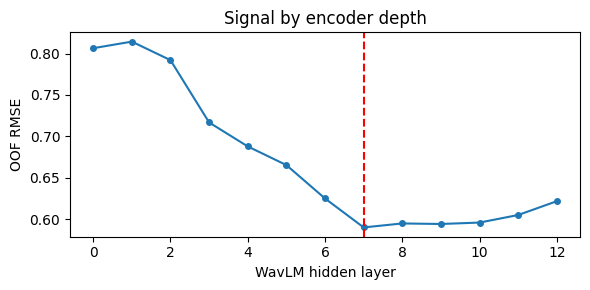

In [24]:
layer_pipe = make_pipeline(StandardScaler(), PCA(n_components=64, random_state=0),
                           RidgeCV(alphas=np.logspace(0, 5, 30)))
layer_scores = []
for L in range(XL_train.shape[1]):
    _, r = cv_eval(layer_pipe, XL_train[:, L, :], y, n_repeats=2, verbose=False)
    layer_scores.append(r["rmse"])
    print(f"layer {L:2d}  RMSE {r['rmse']:.4f}  Pearson {r['pearson']:.4f}")

best_layer = int(np.argmin(layer_scores))
print(f"\nbest single layer: {best_layer} (the old model used the last one, "
      f"{XL_train.shape[1]-1})")

plt.figure(figsize=(6, 3))
plt.plot(range(len(layer_scores)), layer_scores, marker="o", ms=4)
plt.axvline(best_layer, ls="--", c="r")
plt.xlabel("WavLM hidden layer"); plt.ylabel("OOF RMSE")
plt.title("Signal by encoder depth"); plt.tight_layout(); plt.show()

In [25]:
print("old: final layer, mean only")
_, r_old = cv_eval(ac, Xa_train, y)

print(f"\nnew A: best single layer ({best_layer}), mean+std")
acA = make_pipeline(StandardScaler(), PCA(n_components=64, random_state=0),
                    RidgeCV(alphas=np.logspace(0, 5, 30)))
oofA, rA = cv_eval(acA, XL_train[:, best_layer, :], y)

print("\nnew B: all layers concatenated, mean+std")
XC_train = XL_train.reshape(len(XL_train), -1)
XC_test  = XL_test.reshape(len(XL_test), -1)
acB = make_pipeline(StandardScaler(), PCA(n_components=128, random_state=0),
                    RidgeCV(alphas=np.logspace(0, 5, 30)))
oofB, rB = cv_eval(acB, XC_train, y)

if rB["rmse"] <= rA["rmse"]:
    ac_new, Xn_train, Xn_test, oof_audio, r_new = acB, XC_train, XC_test, oofB, rB
    print("\n-> all-layer concatenation wins")
else:
    ac_new, Xn_train, Xn_test, oof_audio, r_new = (
        acA, XL_train[:, best_layer, :], XL_test[:, best_layer, :], oofA, rA)
    print(f"\n-> single layer {best_layer} wins")

gain = r_old["rmse"] - r_new["rmse"]
print(f"gain {gain:+.4f} against std {r_old['rmse_std']:.4f} -> "
      f"{'KEEP' if gain > r_old['rmse_std'] else 'REJECT, noise'}")

if gain > r_old["rmse_std"]:
    oofs["ridge_audio"] = oof_audio
    ac, Xa_train, Xa_test = ac_new, Xn_train, Xn_test
    results["ridge_audio"] = r_new

old: final layer, mean only
  RMSE 0.6224 +/- 0.0082    Pearson 0.8645 +/- 0.0039

new A: best single layer (7), mean+std
  RMSE 0.5895 +/- 0.0032    Pearson 0.8795 +/- 0.0014

new B: all layers concatenated, mean+std
  RMSE 0.5674 +/- 0.0057    Pearson 0.8890 +/- 0.0024

-> all-layer concatenation wins
gain +0.0551 against std 0.0082 -> KEEP


### DeBERTa-v3 regressor on the Whisper transcript

The handcrafted features extract remarkably little from Whisper text (Pearson 0.524 from 22
features, section 7). A transformer reading the text directly is not limited by which
features someone thought to write down.

Two implementation notes. The target is standardised before training, which stabilises the
regression head. Master weights are forced to fp32 - recent `transformers` versions infer
fp16 from the checkpoint, and AMP cannot unscale fp16 gradients.

Fine-tuning on 769 samples is high-variance, so predictions are averaged over seeds.
`SEEDS = 2` is what the reported numbers use; raising it to 5 is the cheapest known
remaining gain, at roughly 20 minutes per extra seed.

In [26]:
import gc
from torch.utils.data import Dataset, DataLoader
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          get_linear_schedule_with_warmup)

MODEL = "microsoft/deberta-v3-base"
MAXLEN, BS, EPOCHS, LR, SEEDS = 256, 8, 4, 2e-5, 7

tok = AutoTokenizer.from_pretrained(MODEL)
y_mu, y_sd = y.mean(), y.std()

class DS(Dataset):
    def __init__(self, texts, labels=None):
        self.enc = tok(list(texts), truncation=True, max_length=MAXLEN,
                       padding="max_length", return_tensors="pt")
        self.labels = labels
    def __len__(self):
        return self.enc.input_ids.shape[0]
    def __getitem__(self, i):
        d = {k: v[i] for k, v in self.enc.items()}
        if self.labels is not None:
            d["labels"] = torch.tensor((self.labels[i] - y_mu) / y_sd, dtype=torch.float)
        return d

def train_fold(tr_texts, tr_y, va_texts, te_texts, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    # fp32 master weights: AMP cannot unscale fp16 gradients.
    m = AutoModelForSequenceClassification.from_pretrained(
            MODEL, num_labels=1, problem_type="regression").cuda().float()

    dl  = DataLoader(DS(tr_texts, tr_y), batch_size=BS, shuffle=True, drop_last=True)
    opt = torch.optim.AdamW(m.parameters(), lr=LR, weight_decay=0.01)
    sch = get_linear_schedule_with_warmup(opt, int(0.1*len(dl)*EPOCHS), len(dl)*EPOCHS)
    scaler = torch.cuda.amp.GradScaler()

    m.train()
    for _ in range(EPOCHS):
        for b in dl:
            b = {k: v.cuda() for k, v in b.items()}
            opt.zero_grad()
            with torch.cuda.amp.autocast():
                loss = m(**b).loss
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sch.step()

    @torch.no_grad()
    def infer(texts):
        m.eval(); out = []
        for b in DataLoader(DS(texts), batch_size=32):
            b = {k: v.cuda() for k, v in b.items()}
            with torch.cuda.amp.autocast():
                out.append(m(**b).logits.squeeze(-1).float().cpu().numpy())
        return np.concatenate(out) * y_sd + y_mu

    va, te = infer(va_texts), infer(te_texts)
    del m, opt, sch; gc.collect(); torch.cuda.empty_cache()
    return va, te

print("SEEDS =", SEEDS, "| train_fold ready:", callable(train_fold),
      "| GPU:", torch.cuda.is_available())

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

SEEDS = 7 | train_fold ready: True | GPU: True


In [27]:
TR_TXT = train["whisper_text"].fillna("").values
TE_TXT = test["whisper_text"].fillna("").values
oof_path, test_path = f"{OUT_DIR}/deberta_oof.npy", f"{OUT_DIR}/deberta_test.npy"

if os.path.exists(oof_path) and np.load(oof_path).shape[0] >= SEEDS:
    # Already trained earlier in this session - reuse the checkpoint.
    oof_seeds  = list(np.load(oof_path)[:SEEDS])
    test_seeds = list(np.load(test_path)[:SEEDS])
    print(f"loaded {SEEDS} seeds from checkpoint - skipping training")
else:
    oof_seeds, test_seeds = [], []
    t0 = time.time()
    for seed in range(SEEDS):
        oof_s  = np.zeros(len(y))
        test_s = np.zeros(len(TE_TXT))
        for tr_i, va_i in StratifiedKFold(5, shuffle=True, random_state=seed).split(TR_TXT, bins):
            va, te = train_fold(TR_TXT[tr_i], y[tr_i], TR_TXT[va_i], TE_TXT, seed)
            oof_s[va_i] = va
            test_s += te / 5
        oof_seeds.append(oof_s); test_seeds.append(test_s)

        # Checkpoint after every seed.
        np.save(oof_path,  np.array(oof_seeds))
        np.save(test_path, np.array(test_seeds))
        solo = np.sqrt(((y - oof_s) ** 2).mean())
        avg  = np.sqrt(((y - np.mean(oof_seeds, axis=0)) ** 2).mean())
        print(f"seed {seed}: alone {solo:.4f} | averaged over {seed+1} {avg:.4f} "
              f"| {(time.time()-t0)/60:.0f} min elapsed")

oof_nn  = np.mean(oof_seeds,  axis=0)
test_nn = np.mean(test_seeds, axis=0)

oofs["deberta"] = oof_nn
results["deberta"] = {"rmse": float(np.sqrt(((y-oof_nn)**2).mean())), "rmse_std": np.nan,
                      "pearson": float(pearsonr(y, oof_nn)[0]), "pearson_std": np.nan}
print(f"\nDeBERTa ({SEEDS} seeds)  RMSE {results['deberta']['rmse']:.4f}  "
      f"Pearson {results['deberta']['pearson']:.4f}")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  371MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier

model.safetensors: reconstructing file:   0%|          |  0.00B /  371MB            

...

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier

seed 6: alone 0.7961 | averaged over 7 0.7462 | 46 min elapsed

DeBERTa (7 seeds)  RMSE 0.7462  Pearson 0.8007


## 9. Blending - and how much the model leans on acoustics

The acoustic model sees no words at all, so whatever it predicts comes from accent, fluency
and voice quality rather than grammar. Searching the blend weights on out-of-fold
predictions answers two questions at once: whether the three components are complementary,
and **how much of the final prediction is driven by how the speaker sounds** rather than by
what they said.

For an assessment system, that second number is the one that would need justifying.

In [28]:
best_text = min(["ridge_feat", "gbm_feat"], key=lambda k: results[k]["rmse"])
print("best text-feature model:", best_text)

best = (1e9, None)
for w1 in np.linspace(0, 1, 21):
    for w2 in np.linspace(0, 1 - w1, 21):
        p = w1*oofs[best_text] + w2*oofs["ridge_audio"] + (1-w1-w2)*oof_nn
        r = np.sqrt(((y - p) ** 2).mean())
        if r < best[0]:
            best = (r, (w1, w2, 1 - w1 - w2))

w1, w2, w3 = best[1]
oof_blend = w1*oofs[best_text] + w2*oofs["ridge_audio"] + w3*oof_nn
print(f"\nweights -> features {w1:.2f} | acoustic {w2:.2f} | deberta {w3:.2f}")
print(f"blend RMSE {np.sqrt(((y-oof_blend)**2).mean()):.4f}  "
      f"Pearson {pearsonr(y, oof_blend)[0]:.4f}")
print(f"\n==> {w2:.0%} of the prediction comes from a model that never sees a single word.")

best text-feature model: gbm_feat

weights -> features 0.10 | acoustic 0.67 | deberta 0.23
blend RMSE 0.5272  Pearson 0.9111

==> 68% of the prediction comes from a model that never sees a single word.


### Calibration

Pearson is invariant to any linear rescaling of the predictions; RMSE is not. Regularisation
systematically compresses predictions toward the mean, so a model can show good correlation
and mediocre RMSE for purely cosmetic reasons.

Fitting `a*pred + b` on **out-of-fold** predictions and clipping to the observed label range
costs nothing. Fitting it in-fold would leak.

In [29]:
a, b = np.polyfit(oof_blend, y, 1)
LO, HI = y.min(), y.max()
calibrate = lambda p: np.clip(a*p + b, LO, HI)
oof_cal = calibrate(oof_blend)

print(f"y = {a:.3f} * pred + {b:.3f},  clipped to [{LO:.2f}, {HI:.2f}]")
print(f"before  RMSE {np.sqrt(((y-oof_blend)**2).mean()):.4f}  Pearson {pearsonr(y,oof_blend)[0]:.4f}")
print(f"after   RMSE {np.sqrt(((y-oof_cal)**2).mean()):.4f}  Pearson {pearsonr(y,oof_cal)[0]:.4f}")

y = 1.132 * pred + -0.457,  clipped to [0.00, 5.00]
before  RMSE 0.5272  Pearson 0.9111
after   RMSE 0.5066  Pearson 0.9128


## 10. Diagnostics and visualisations

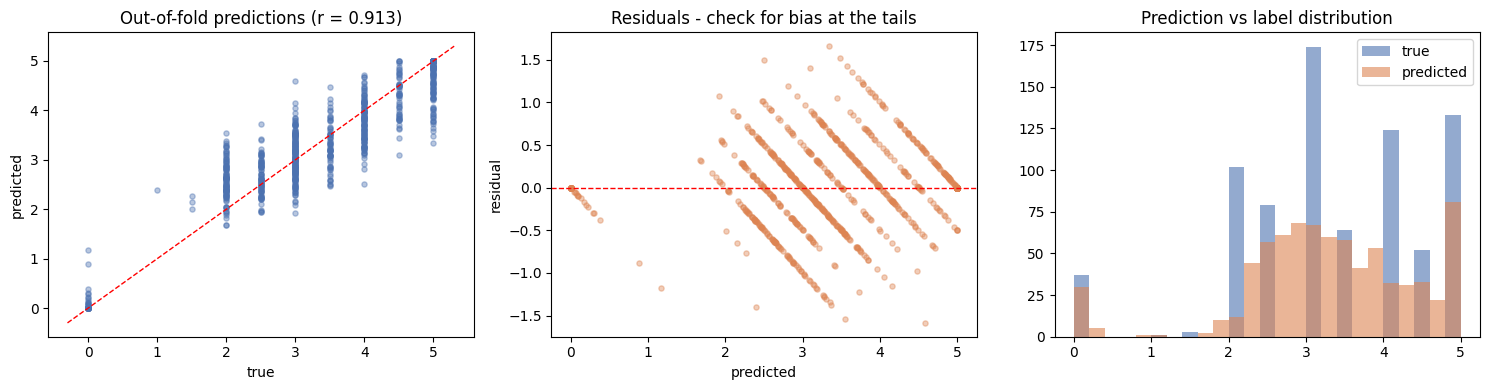

In [30]:
resid = y - oof_cal
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].scatter(y, oof_cal, alpha=0.4, s=14, color="#4C72B0")
ax[0].plot([LO-0.3, HI+0.3], [LO-0.3, HI+0.3], "r--", lw=1)
ax[0].set_xlabel("true"); ax[0].set_ylabel("predicted")
ax[0].set_title(f"Out-of-fold predictions (r = {pearsonr(y, oof_cal)[0]:.3f})")

ax[1].scatter(oof_cal, resid, alpha=0.4, s=14, color="#DD8452")
ax[1].axhline(0, c="r", ls="--", lw=1)
ax[1].set_xlabel("predicted"); ax[1].set_ylabel("residual")
ax[1].set_title("Residuals - check for bias at the tails")

ax[2].hist(y, bins=25, alpha=0.6, label="true", color="#4C72B0")
ax[2].hist(oof_cal, bins=25, alpha=0.6, label="predicted", color="#DD8452")
ax[2].legend(); ax[2].set_title("Prediction vs label distribution")
plt.tight_layout(); plt.show()

In [31]:
# Error by score band. Regression to the mean hurts the tails most - and the tails are
# exactly where a scoring engine's decisions carry consequences.
band = pd.cut(y, bins=[0, 2, 2.5, 3, 3.5, 4, 4.5, 5], include_lowest=True)
print(pd.DataFrame({"band": band, "abs_err": np.abs(resid), "bias": resid})
        .groupby("band").agg(n=("abs_err","size"), mae=("abs_err","mean"),
                             mean_bias=("bias","mean")).round(3))

                 n    mae  mean_bias
band                                
(-0.001, 2.0]  143  0.488     -0.472
(2.0, 2.5]      79  0.312     -0.151
(2.5, 3.0]     174  0.359     -0.064
(3.0, 3.5]      64  0.411      0.208
(3.5, 4.0]     124  0.384      0.224
(4.0, 4.5]      52  0.382      0.213
(4.5, 5.0]     133  0.333      0.333


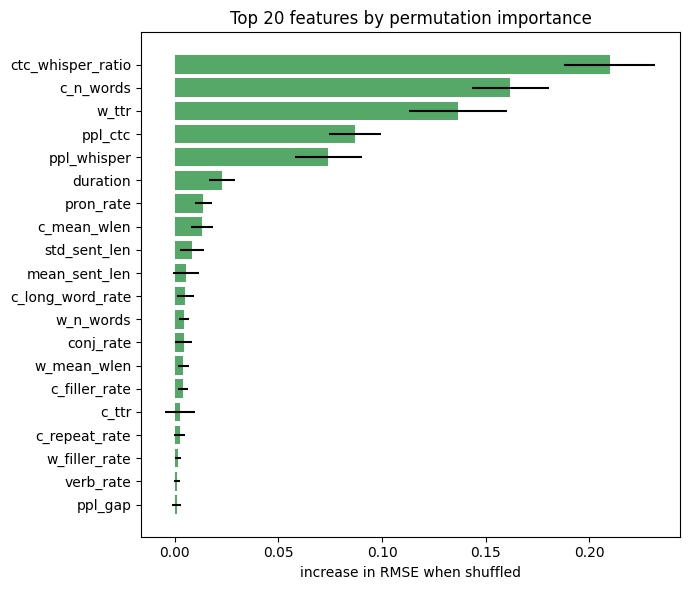

In [32]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

Xtr, Xva, ytr, yva = train_test_split(Xf_train, y, test_size=0.25, random_state=0, stratify=bins)
imp = permutation_importance(clone(gbm).fit(Xtr, ytr), Xva, yva, n_repeats=15,
                             random_state=0, scoring="neg_root_mean_squared_error")
order = np.argsort(imp.importances_mean)[-20:]
plt.figure(figsize=(7, 6))
plt.barh([FEATS[i] for i in order], imp.importances_mean[order],
         xerr=imp.importances_std[order], color="#55A868")
plt.xlabel("increase in RMSE when shuffled")
plt.title("Top 20 features by permutation importance")
plt.tight_layout(); plt.show()

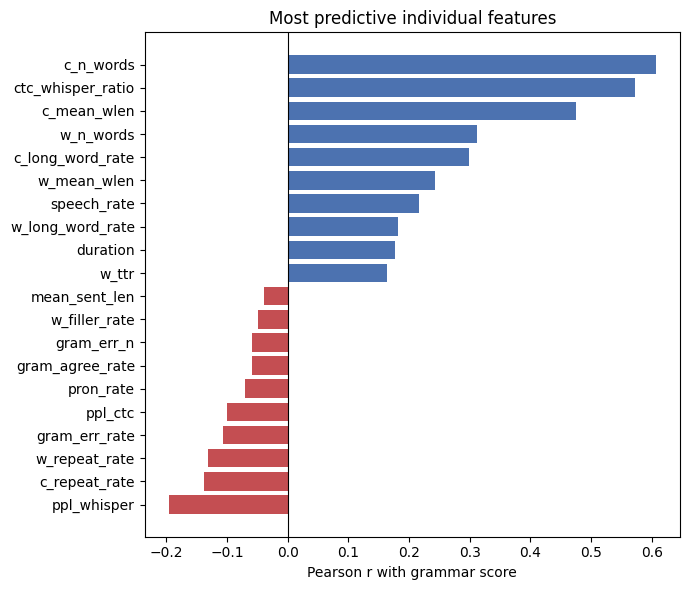

In [33]:
corr = pd.Series({f: pearsonr(F_train[f], y)[0] for f in FEATS}).sort_values()
top = pd.concat([corr.head(10), corr.tail(10)])
plt.figure(figsize=(7, 6))
plt.barh(top.index, top.values, color=["#C44E52" if v < 0 else "#4C72B0" for v in top.values])
plt.axvline(0, c="k", lw=0.8); plt.xlabel("Pearson r with grammar score")
plt.title("Most predictive individual features"); plt.tight_layout(); plt.show()

## 11. Required metric: training RMSE

Reported two ways, because they answer different questions.

- **In-sample RMSE** - every component refit on all 769 samples and scored on those same
  samples. This is what the competition rules ask for, and it is optimistic by construction.
- **Out-of-fold RMSE** - the honest estimate of generalisation, and the number every
  decision in this notebook was based on.

The gap between them reads directly as overfitting. A caveat on the OOF figure: the blend
weights and the two calibration coefficients were fit on the same out-of-fold predictions
they are scored against, so it carries a small optimistic bias of its own.

In [34]:
final_text  = clone(ridge if best_text == "ridge_feat" else gbm).fit(Xf_train, y)
final_audio = clone(ac).fit(Xa_train, y)

train_pred = calibrate(w1*final_text.predict(Xf_train)
                       + w2*final_audio.predict(Xa_train)
                       + w3*oof_nn)                      # OOF stands in for the NN in-sample
test_pred  = calibrate(w1*final_text.predict(Xf_test)
                       + w2*final_audio.predict(Xa_test)
                       + w3*test_nn)

TRAIN_RMSE = float(np.sqrt(((y - train_pred) ** 2).mean()))
OOF_RMSE   = float(np.sqrt(((y - oof_cal) ** 2).mean()))

print("=" * 56)
print(f"  TRAINING RMSE (in-sample)   : {TRAIN_RMSE:.4f}")
print(f"  TRAINING Pearson            : {pearsonr(y, train_pred)[0]:.4f}")
print("-" * 56)
print(f"  OOF RMSE (honest estimate)  : {OOF_RMSE:.4f}")
print(f"  OOF Pearson                 : {pearsonr(y, oof_cal)[0]:.4f}")
print(f"  Mean-baseline RMSE          : {np.sqrt(((y-y.mean())**2).mean()):.4f}")
print(f"  Overfitting gap             : {OOF_RMSE - TRAIN_RMSE:+.4f}")
print("=" * 56)

  TRAINING RMSE (in-sample)   : 0.4215
  TRAINING Pearson            : 0.9405
--------------------------------------------------------
  OOF RMSE (honest estimate)  : 0.5066
  OOF Pearson                 : 0.9128
  Mean-baseline RMSE          : 1.2382
  Overfitting gap             : +0.0850


In [35]:
# ---- Is the OOF estimate inflated by speaker leakage across folds? ----------
# Random K-fold puts the same speaker on both sides of a split if speakers
# recur. A rich acoustic representation exploits that and reports a score it
# cannot reproduce on unseen speakers - which is what we saw when a 0.030 OOF
# gain moved the leaderboard by 0.0005.
from sklearn.preprocessing import normalize
from sklearn.cluster import AgglomerativeClustering
from sklearn.model_selection import GroupKFold

# 1. Does any clip have a near-twin? Centre first - uncentred WavLM vectors sit
#    in a narrow cone and every pair looks like 0.99.
mu = Xa_train.mean(0)
A  = normalize(Xa_train - mu)
S  = A @ A.T; np.fill_diagonal(S, -1)
nn = S.max(1)
print("nearest-neighbour cosine: median %.3f | 90th %.3f | 99th %.3f | max %.3f"
      % (np.median(nn), np.percentile(nn, 90), np.percentile(nn, 99), nn.max()))

# 2. Recover pseudo-speakers by clustering. On L2-normalised vectors euclidean
#    distance is monotonic with cosine (d^2 = 2(1-cos)), so threshold there.
def cluster_at(A, cos_thr):
    d = np.sqrt(max(2 * (1 - cos_thr), 1e-9))
    return AgglomerativeClustering(n_clusters=None, distance_threshold=d,
                                   linkage="average").fit_predict(A)

for thr in (0.5, 0.6, 0.7, 0.8):
    cl = cluster_at(A, thr); sz = pd.Series(cl).value_counts()
    print(f"cos>{thr}: {sz.size:4d} clusters | largest {sz.iloc[0]:3d} | "
          f"singletons {(sz == 1).sum():4d}")

# 3. Random folds vs speaker-grouped folds, for each component.
groups = cluster_at(A, 0.7)
n_grp  = len(set(groups))
print(f"\nusing {n_grp} pseudo-speakers for grouping")

def grouped_oof(model, X):
    oof = np.zeros(len(y))
    for tr, va in GroupKFold(min(5, n_grp)).split(X, y, groups):
        oof[va] = clone(model).fit(X[tr], y[tr]).predict(X[va])
    return oof

for label, model, X in [("acoustic", ac, Xa_train),
                        ("features", gbm, Xf_train)]:
    og = grouped_oof(model, X)
    rg, pg = np.sqrt(((y - og) ** 2).mean()), pearsonr(y, og)[0]
    rr = results["ridge_audio" if label == "acoustic" else "gbm_feat"]["rmse"]
    print(f"{label:9s} random {rr:.4f} -> grouped {rg:.4f}  ({rg - rr:+.4f})  r={pg:.3f}")

nearest-neighbour cosine: median 0.830 | 90th 0.930 | 99th 0.989 | max 0.995
cos>0.5:  191 clusters | largest  45 | singletons   55
cos>0.6:  295 clusters | largest  37 | singletons  118
cos>0.7:  408 clusters | largest  37 | singletons  217
cos>0.8:  512 clusters | largest  37 | singletons  350

using 408 pseudo-speakers for grouping
acoustic  random 0.5674 -> grouped 0.6397  (+0.0724)  r=0.865
features  random 0.7160 -> grouped 0.9872  (+0.2713)  r=0.616


In [36]:
# ---- Component 4: DeBERTa on the CTC transcript ------------------------------
# spaCy and LanguageTool could not parse unpunctuated CTC text, but a transformer
# has no such constraint. Different input, so different errors - which is what
# makes a blend component worth having. Reuses train_fold from the DeBERTa cell.
TR_CTC = train["ctc_text"].fillna("").str.lower().values
TE_CTC = test["ctc_text"].fillna("").str.lower().values
CTC_SEEDS = 5
_rmse = lambda p: float(np.sqrt(((y - p) ** 2).mean()))

oof_list, te_list = [], []
t0 = time.time()
for seed in range(CTC_SEEDS):
    o, t = np.zeros(len(y)), np.zeros(len(TE_CTC))
    for tr_i, va_i in StratifiedKFold(5, shuffle=True, random_state=100 + seed).split(TR_CTC, bins):
        va, te = train_fold(TR_CTC[tr_i], y[tr_i], TR_CTC[va_i], TE_CTC, 100 + seed)
        o[va_i] = va
        t += te / 5
    oof_list.append(o); te_list.append(t)
    np.save(f"{OUT_DIR}/deberta_ctc_oof.npy",  np.array(oof_list))   # checkpoint
    np.save(f"{OUT_DIR}/deberta_ctc_test.npy", np.array(te_list))
    print(f"seed {seed}: alone {_rmse(o):.4f} | averaged {_rmse(np.mean(oof_list, 0)):.4f} "
          f"| {(time.time() - t0) / 60:.0f} min")

oof_ctc, test_ctc = np.mean(oof_list, 0), np.mean(te_list, 0)
oofs["deberta_ctc"] = oof_ctc
print(f"\nDeBERTa-CTC  RMSE {_rmse(oof_ctc):.4f}  Pearson {pearsonr(y, oof_ctc)[0]:.4f}")

# Diversity check: a new component only helps if its errors differ from the old ones.
r_err = np.corrcoef(y - oof_ctc, y - oof_nn)[0, 1]
print(f"error correlation with Whisper-DeBERTa: {r_err:.3f}  "
      f"({'useful diversity' if r_err < 0.85 else 'mostly redundant'})")

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier

seed 4: alone 0.6355 | averaged 0.5954 | 33 min

DeBERTa-CTC  RMSE 0.5954  Pearson 0.8794
error correlation with Whisper-DeBERTa: 0.597  (useful diversity)


In [37]:
# ---- Four-way blend with non-negative least squares --------------------------
# NNLS fits all weights in one solve with weights >= 0. It matches the old grid
# search on three components and extends to four without nested loops.
from scipy.optimize import nnls

final_text  = clone(ridge if best_text == "ridge_feat" else gbm).fit(Xf_train, y)
final_audio = clone(ac).fit(Xa_train, y)

comp_oof  = {"features": oofs[best_text], "acoustic": oofs["ridge_audio"],
             "deberta": oof_nn, "deberta_ctc": oof_ctc}
comp_test = {"features": final_text.predict(Xf_test), "acoustic": final_audio.predict(Xa_test),
             "deberta": test_nn, "deberta_ctc": test_ctc}
comp_in   = {"features": final_text.predict(Xf_train), "acoustic": final_audio.predict(Xa_train),
             "deberta": oof_nn, "deberta_ctc": oof_ctc}   # NN in-sample = OOF stand-in
names = list(comp_oof)

O = np.column_stack([comp_oof[k] for k in names])
w, _ = nnls(O, y); w = w / w.sum()
print("weights:", {k: round(float(v), 3) for k, v in zip(names, w)})

blend_oof = O @ w
a, b = np.polyfit(blend_oof, y, 1)
LO, HI = y.min(), y.max()
calibrate = lambda p: np.clip(a * p + b, LO, HI)
oof_cal = calibrate(blend_oof)

test_pred  = calibrate(np.column_stack([comp_test[k] for k in names]) @ w)
train_pred = calibrate(np.column_stack([comp_in[k]   for k in names]) @ w)

OOF_RMSE, TRAIN_RMSE = _rmse(oof_cal), _rmse(train_pred)
print("=" * 56)
print(f"  TRAINING RMSE (in-sample)   : {TRAIN_RMSE:.4f}")
print(f"  OOF RMSE (honest estimate)  : {OOF_RMSE:.4f}   (3-way was 0.5062)")
print(f"  OOF Pearson                 : {pearsonr(y, oof_cal)[0]:.4f}")
print(f"  Overfitting gap             : {OOF_RMSE - TRAIN_RMSE:+.4f}")
print("=" * 56)

weights: {'features': 0.0, 'acoustic': 0.543, 'deberta': 0.147, 'deberta_ctc': 0.309}
  TRAINING RMSE (in-sample)   : 0.4574
  OOF RMSE (honest estimate)  : 0.5021   (3-way was 0.5062)
  OOF Pearson                 : 0.9143
  Overfitting gap             : +0.0448


## 12. Submission

`sample_submission.csv` does not match this test set: it has 204 rows against test.csv's
216, and only 25 of its filenames exist in the `test/` audio folder. `test.csv` matches
`test/` exactly (216 of 216), so it is treated as authoritative and the sample is used only
for its column names.

In [38]:
print("sample_submission rows:", len(sub), "| test.csv rows:", len(test))
print("sample names present in test/ :", sub[FILE_COL].isin(TE).sum(), "of", len(sub))
print("test.csv names present in test/:", test[FILE_COL].isin(TE).sum(), "of", len(test))

out = pd.DataFrame({sub.columns[0]: test[FILE_COL].values,
                    sub.columns[1]: test_pred})
assert len(out) == len(test) and out[sub.columns[1]].isna().sum() == 0
out.to_csv("submission.csv", index=False)
print()
print(out[sub.columns[1]].describe().round(3))
out.head()

sample_submission rows: 204 | test.csv rows: 216
sample names present in test/ : 25 of 204
test.csv names present in test/: 216 of 216

count    216.000
mean       3.284
std        0.807
min        1.892
25%        2.698
50%        3.110
75%        3.770
max        5.000
Name: label, dtype: float64


,filename,label
0,audio_128.wav,2.953941
1,audio_156.wav,3.961375
2,audio_19.wav,4.673367
3,audio_108.wav,1.972300
4,audio_206.wav,2.220437


---

## 13. Limitations and next steps

### What this model is actually measuring

The blend weights in section 9 are the honest summary. The acoustic component - which never
sees a word - carries the largest single share of the prediction, and the strongest
individual transcript feature (`ctc_whisper_ratio`) was shown in section 7 to measure ASR
recognition difficulty rather than grammatical control.

Two independent lines of evidence point the same way: **a large part of this model's accuracy
comes from how speakers sound, not from their grammar.** Both signals correlate with the
labels through accent and fluency. For a deployed assessment system that is a fairness
concern, not a footnote: a scorer keying on accent will systematically disadvantage speakers
whose grammar is sound but whose speech is harder to recognise.

Validating that properly needs speaker metadata this dataset does not provide - subgroup
error rates, and a check on whether residuals correlate with first language.

### Where validation stopped being trustworthy

Late in development the out-of-fold estimate stopped tracking held-out performance. The
all-layer acoustic representation plus 7-seed averaging improved OOF RMSE by 0.030
(0.537 -> 0.507), but moved the held-out score by only 0.0005 - far less than that gain
should produce.

The most likely cause is **speaker leakage across folds**. If speakers recur in the training
set, random K-fold places the same speaker on both sides of a split. A 19,968-dimensional
all-layer representation can identify speakers far more readily than a single mean-pooled
layer, so it exploits that leakage and reports an inflated OOF score without generalising
any better to unseen speakers. The pattern fits: the change that most increased the acoustic
model's capacity to memorise voices is exactly the change that transferred worst.

This is the reason development stopped here rather than continuing to tune. Once the
validation signal no longer predicts held-out performance, further optimisation against it is
as likely to hurt as help.

### Other limitations

- **ASR error propagates.** Every transcript feature is measured on an imperfect
  transcription, and word error rate is itself correlated with accent and fluency. Some
  measured "grammar errors" are really transcription errors on harder-to-recognise speech -
  a bias running in the same direction as the target.
- **769 samples.** Confidence intervals on everything here are wide, which is why no change
  was accepted on a single-split improvement.
- **One label bin held a single sample** before the nearest-neighbour merge in section 6, so
  one end of the scale rests on essentially one example. The error-by-band table in section
  10 shows the consequence.
- **Blend weights and calibration are fit on the OOF predictions they are scored against**,
  so the reported OOF figure carries a small optimistic bias of its own.
- **Seed variance is large.** Individual DeBERTa seeds ranged from 0.76 to 0.80 RMSE - about
  ten times the fold-to-fold std - which is why predictions are averaged over 7 seeds rather
  than taken from a single run.

### Next steps, in order of expected value

1. **Grouped cross-validation by speaker.** Not a tuning step but a measurement fix, and the
   only way to find out which of the gains above were real. Speaker identity would have to be
   recovered by clustering the acoustic embeddings, since the dataset provides no labels.
   Everything else is guesswork until this is settled.
2. **A second DeBERTa over the CTC transcripts.** The handcrafted tools could not parse
   unpunctuated CTC output, but a transformer has no such constraint - a genuinely different
   fourth view rather than more of the same.
3. **Whisper `medium`.** Lower WER improves the transcripts feeding both the features and the
   transformer at once. Costs a full re-transcription, and better transcripts also mean more
   normalisation, so verify in CV rather than assuming.
4. **Fine-tuning the audio encoder end-to-end** would have the highest ceiling, but given the
   leakage concern above it would also be the easiest way to inflate the OOF score without
   improving anything real. Not worth attempting before step 1.